# Data Validation

## 2.1 Duplicate Data

In [1]:
if (!requireNamespace("pacman", quietly = TRUE)) {
  install.packages("pacman")
}
library(pacman)
pacman::p_load(tidyverse, lubridate, ggplot2, dplyr)


In [2]:
uw_data <- read_csv("DuplicateData/underwriting_data.csv")
uw_data

Rows: 22 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ApplicationID, PolicyType, ApplicantCity
dbl (3): RiskScore, PremiumQuote, UnderwritingScore

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


ApplicationID,PolicyType,RiskScore,PremiumQuote,ApplicantCity,UnderwritingScore
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>
A2024-001,Auto,75,1200,Dallas,75
A2024-002,Home,42,450,Austin,42
A2024-003,Renters,88,800,Houston,88
A2024-004,Auto,30,1500,Dallas,30
A2024-005,Home,65,600,Austin,65
A2024-006,Renters,55,750,Houston,55
A2024-007,Auto,92,950,Dallas,92
A2024-008,Home,48,520,Austin,48
A2024-009,Renters,70,1100,Houston,70


In [3]:
unique(uw_data)

ApplicationID,PolicyType,RiskScore,PremiumQuote,ApplicantCity,UnderwritingScore
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>
A2024-001,Auto,75,1200,Dallas,75
A2024-002,Home,42,450,Austin,42
A2024-003,Renters,88,800,Houston,88
A2024-004,Auto,30,1500,Dallas,30
A2024-005,Home,65,600,Austin,65
A2024-006,Renters,55,750,Houston,55
A2024-007,Auto,92,950,Dallas,92
A2024-008,Home,48,520,Austin,48
A2024-009,Renters,70,1100,Houston,70


In [4]:
uw_data %>% filter(!duplicated(ApplicationID))

ApplicationID,PolicyType,RiskScore,PremiumQuote,ApplicantCity,UnderwritingScore
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>
A2024-001,Auto,75,1200,Dallas,75
A2024-002,Home,42,450,Austin,42
A2024-003,Renters,88,800,Houston,88
A2024-004,Auto,30,1500,Dallas,30
A2024-005,Home,65,600,Austin,65
A2024-006,Renters,55,750,Houston,55
A2024-007,Auto,92,950,Dallas,92
A2024-008,Home,48,520,Austin,48
A2024-009,Renters,70,1100,Houston,70


In [5]:
uw_data %>% filter(!duplicated(ApplicationID, fromLast=TRUE))

ApplicationID,PolicyType,RiskScore,PremiumQuote,ApplicantCity,UnderwritingScore
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>
A2024-003,Renters,88,800,Houston,88
A2024-004,Auto,30,1500,Dallas,30
A2024-005,Home,65,600,Austin,65
A2024-006,Renters,55,750,Houston,55
A2024-007,Auto,92,950,Dallas,92
A2024-008,Home,48,520,Austin,48
A2024-009,Renters,70,1100,Houston,70
A2024-010,Auto,35,1350,Dallas,35
A2024-011,Home,75,1200,Austin,75


In [6]:
ncol(unique.matrix(uw_data, MARGIN=2))
unique.matrix(uw_data, MARGIN=2, fromLast=FALSE)

[1] 5

ApplicationID,PolicyType,RiskScore,PremiumQuote,ApplicantCity
<chr>,<chr>,<dbl>,<dbl>,<chr>
A2024-001,Auto,75,1200,Dallas
A2024-002,Home,42,450,Austin
A2024-003,Renters,88,800,Houston
A2024-004,Auto,30,1500,Dallas
A2024-005,Home,65,600,Austin
A2024-006,Renters,55,750,Houston
A2024-007,Auto,92,950,Dallas
A2024-008,Home,48,520,Austin
A2024-009,Renters,70,1100,Houston


## 2.2 Duplicate Data Continued

In [7]:
# pacman::p_load(janitor)
# install.packages("janitor", repos = "https://cran.r-project.org/", dependencies = TRUE )
library(janitor)



Attaching package: 'janitor'


The following objects are masked from 'package:stats':

    chisq.test, fisher.test




In [8]:
load("DuplicateData/fremotor1prem0304a.rda")
df <- data.frame(fremotor1prem0304a)
head(df)

,IDpol,Year,DrivAge,DrivGender,MaritalStatus,BonusMalus,LicenceNb,PayFreq,JobCode,VehAge,⋯,PremDamAll,PremFire,PremAcc1,PremAcc2,PremLegal,PremTPLM,PremTPLV,PremServ,PremTheft,PremTot
,<chr>,<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<fct>,<fct>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1000111.100a,2003,44,F,Cohabiting,50,3,Half-yearly,Private employee,10,⋯,0,0,0,0,6,69.1,4,50,0,144.1
2,1000113.100a,2003,26,F,Cohabiting,85,2,Annual,Other,8,⋯,0,0,0,0,7,139.3,7,46,0,215.3
3,1000113.100b,2003,26,F,Cohabiting,106,2,Half-yearly,Other,9,⋯,0,0,0,0,11,283.0,15,57,0,400.0
4,1000113.100c,2003,27,F,Cohabiting,106,2,Half-yearly,Other,6,⋯,0,0,0,0,17,453.6,24,57,0,611.6
5,1000173.100a,2003,52,M,Cohabiting,50,2,Half-yearly,Private employee,2,⋯,125,5,0,47,9,111.2,5,48,50,415.2
6,1000173.101a,2003,52,M,Cohabiting,50,2,Half-yearly,Private employee,1,⋯,167,8,0,0,11,132.8,7,48,90,487.8


In [9]:
duplicate_pol <- duplicated(df$IDpol)
summary(duplicate_pol)

   Mode   FALSE    TRUE 
logical   32117   19832 

In [10]:
duplicate_polyear <- duplicated(df[, c("IDpol", "Year")])
summary(duplicate_polyear)

   Mode   FALSE    TRUE 
logical   51943       6 

In [11]:
(df_dupes <- df %>% get_dupes(IDpol, Year))

IDpol,Year,dupe_count,DrivAge,DrivGender,MaritalStatus,BonusMalus,LicenceNb,PayFreq,JobCode,⋯,PremDamAll,PremFire,PremAcc1,PremAcc2,PremLegal,PremTPLM,PremTPLV,PremServ,PremTheft,PremTot
<chr>,<dbl>,<int>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<fct>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
90111147.101b,2003,2,44,F,Cohabiting,50,2,Half-yearly,Public employee,⋯,88,4,0,48,8,98.3,5,52,41,360.3
90111147.101b,2003,2,44,F,Single,50,2,Half-yearly,Private employee,⋯,96,4,0,52,9,107.1,5,57,45,392.1
90111147.102a,2004,2,45,M,Single,81,2,Half-yearly,Private employee,⋯,0,7,0,0,10,200.9,11,52,68,379.9
90111147.102a,2004,2,45,M,Cohabiting,81,2,Half-yearly,Private employee,⋯,0,8,0,0,11,219.0,12,57,74,415.0
90132938.100a,2003,2,39,M,NA,50,2,Half-yearly,NA,⋯,108,5,0,48,8,102.6,5,52,51,412.6
90132938.100a,2003,2,39,M,NA,50,2,Half-yearly,NA,⋯,118,5,0,52,9,111.8,5,57,56,449.8
90132938.101b,2004,2,36,F,NA,50,2,Half-yearly,NA,⋯,58,2,27,0,5,64.8,4,49,22,240.8
90132938.101b,2004,2,36,F,NA,50,2,Half-yearly,NA,⋯,63,2,29,0,5,70.6,4,53,24,260.6
90152419.101a,2003,2,53,M,NA,50,2,Half-yearly,NA,⋯,119,6,32,0,10,121.0,6,48,61,430.0


## 2.3 Outliers

In [12]:
diamonds_data <- as_tibble(diamonds)

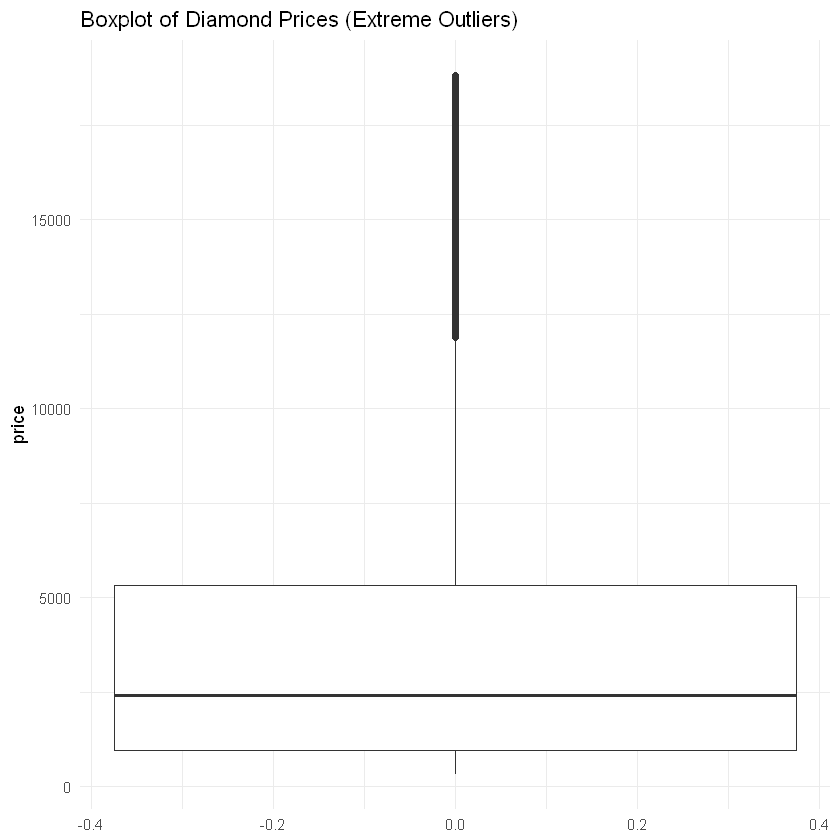

In [ ]:
diamonds_data |>
  ggplot(mapping = aes(y = price)) +
  geom_boxplot() +
  ggtitle("Boxplot of Diamond Prices (Extreme Outliers)") +
  theme_minimal()

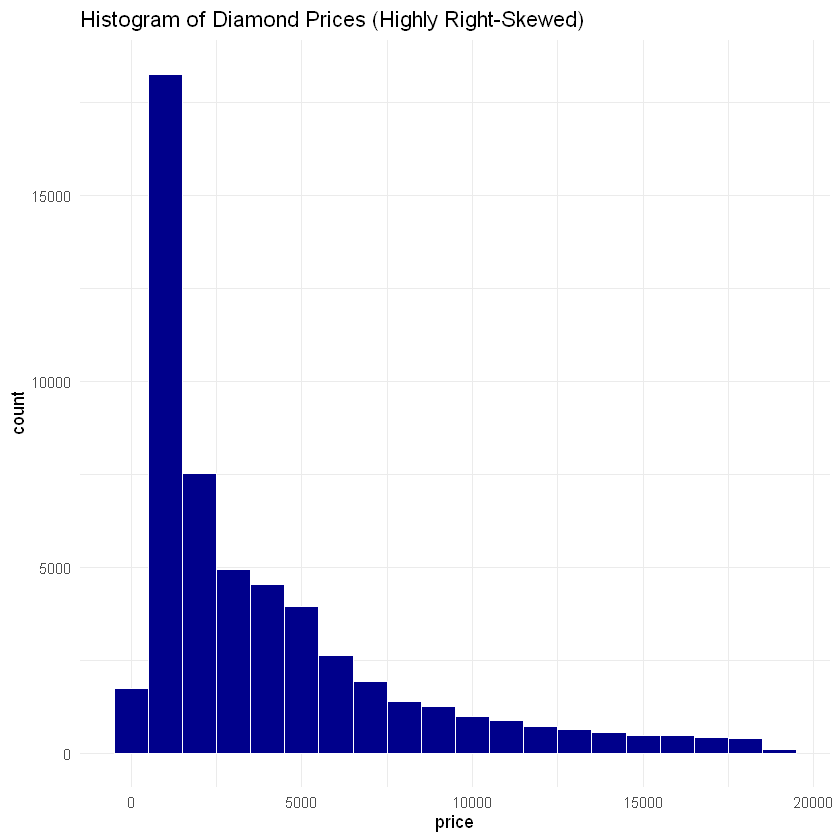

In [21]:
diamonds_data |>
  ggplot(mapping = aes(x = price)) +
  geom_histogram(binwidth = 1000, fill = "darkblue", color = "white") +
  ggtitle("Histogram of Diamond Prices (Highly Right-Skewed)") +
  theme_minimal()

There are a number of outliers in the tail end.

Thus, we identify outliers based on the IQR

In [43]:
q1 <- quantile(diamonds_data$price, 0.25)
q3 <- quantile(diamonds_data$price, 0.75)
iqr_val <- q3 - q1

cutoff_upper <- q3 + 1.5 * iqr_val
cutoff_lower <- q1 - 1.5 * iqr_val

num_outliers <- diamonds_data |>
  filter(price > cutoff_upper | price < cutoff_lower) |>
  nrow()

cat(paste("Q1 (25th Percentile):", round(q1, 2), "\n"))
cat(paste("Q3 (75th Percentile):", round(q3, 2), "\n"))
cat(paste("IQR (Q3 - Q1):", round(iqr_val, 2), "\n"))
cat(paste("Upper outlier Cutoff (Q3 + 1.5*IQR):", round(cutoff_upper, 2), "\n"))
cat(paste("Lower outlier Cutoff (Q1 - 1.5*IQR):", round(cutoff_lower, 2), "\n"))
cat(paste("Total number of rows:", nrow(diamonds_data), "\n"))
cat(paste("Numbers of outliers identified:", num_outliers, "\n"))
cat(
  paste(
    "Percentage of outliers:",
    round(num_outliers / nrow(diamonds_data) * 100, 2), "%\n"
  )
)

Q1 (25th Percentile): 950 
Q3 (75th Percentile): 5324.25 
IQR (Q3 - Q1): 4374.25 
Upper outlier Cutoff (Q3 + 1.5*IQR): 11885.62 
Lower outlier Cutoff (Q1 - 1.5*IQR): -5611.38 
Total number of rows: 53940 
Numbers of outliers identified: 3540 
Percentage of outliers: 6.56 %


In [46]:
diamonds_removed <- diamonds_data |>
  filter(price <= cutoff_upper & price >= cutoff_lower)

cat(
  paste(
    "Observations removed:",
    nrow(diamonds_data) - nrow(diamonds_removed),
    "\n"
  )
)
cat(paste("Observations remaining:", nrow(diamonds_data), "\n"))

Observations removed: 3540 
Observations remaining: 53940 


**Transform data**

In [50]:
diamonds_logged <- diamonds_data |>
  mutate(price_log = log(price))

cat("Minimum Log price:", round(min(diamonds_logged$price_log), 3), "\n")
cat("Maximum Log price", round(max(diamonds_logged$price_log), 3), "\n")

Minimum Log price: 5.787 
Maximum Log price 9.843 


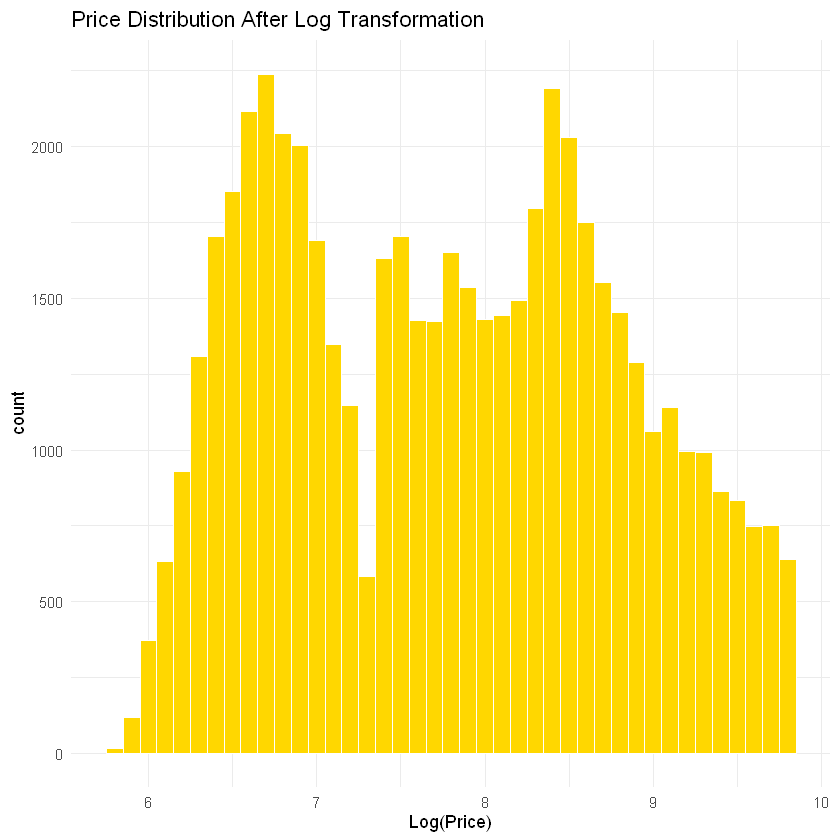

In [60]:
diamonds_logged |>
  ggplot(mapping = aes(x = price_log)) +
  geom_histogram(fill = "gold", color = "white", binwidth = 0.1) +
  labs(
    title = "Price Distribution After Log Transformation",
    x = "Log(Price)"
  ) +
  theme_minimal()

We are losing some interpretability, but we are not losing out on data.

If interpretability is more important, then we should use a different approach than log transformations.

**Cap Values**

In [64]:
cap_percentile <- 0.95
cap_value <- quantile(diamonds_data$price, cap_percentile)

diamonds_capped <- diamonds_data |>
  mutate(price_capped = pmin(price, cap_value))

cat("Capping Price at the 95th percentile (Value: ", round(cap_value, 2), ")\n")

Capping Price at the 95th percentile (Value:  13107.1 )


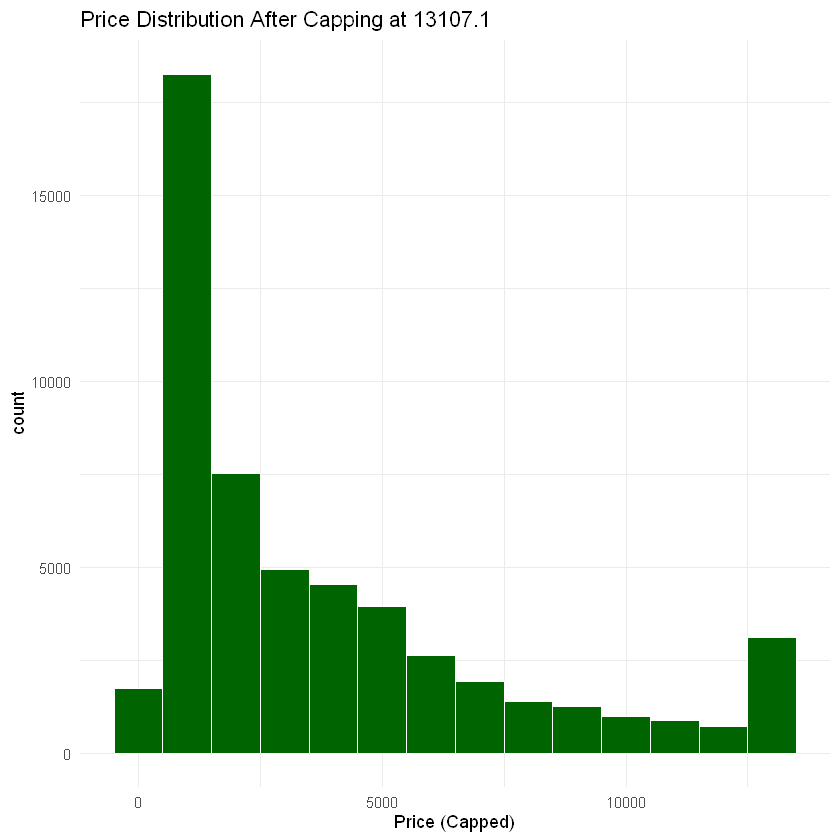

In [66]:
diamonds_capped |>
  ggplot(mapping = aes(x = price_capped)) +
  geom_histogram(binwidth = 1000, fill="darkgreen", color="white") +
  labs(
    title = str_c("Price Distribution After Capping at ", round(cap_value, 2)),
    x = "Price (Capped)"
  ) +
  theme_minimal()

Since we are capping it at 13107, the numbers get accumulated at the tail (identified at the thick tail histogram)

**Replace Variable with Percentiles**

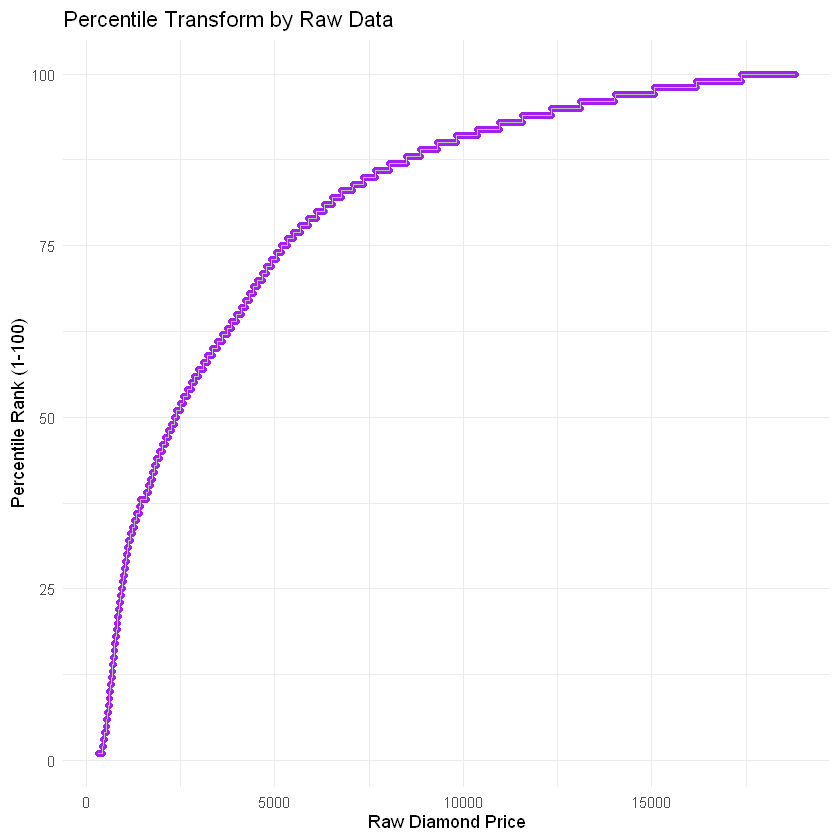

In [68]:
diamonds_data |>
  mutate(price_percentile = ntile(price, 100)) |>
  ggplot(mapping = aes(x = price, y = price_percentile)) +
  geom_point(color = "purple", alpha = 0.5) +
  geom_line(color = "gray") +
  labs(x = "Raw Diamond Price", y = "Percentile Rank (1-100)") +
  ggtitle("Percentile Transform by Raw Data") +
  theme_minimal()

Replace the values by percentiles.

- Extreme values are not going to seem as extreme (compresses the distance)
- When we don't need to the value of the outliers, but just know that they are large.
- Doesn't affect the more typical observations

In [ ]:
ntile(diamonds_data$price, 100)

[1]   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1
   [19]   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1
   [37]   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1
   [55]   1   1   1   1   1   1   6   6   6   6   6   6   6   6   6   6   6   6
   [73]   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
   [91]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [109]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [127]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [145]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [163]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [181]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [199]  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54  54
  [217]  54  54  54  54  54  54  54  54  54  54  55  55  55  55  55  55  55  55
  [235]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [253]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [271]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [289]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [307]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [325]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [343]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [361]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [379]  55  55  55  55  55  55  55  55  55  55  55  55   6   6   6   6   6   6
  [397]   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
  [415]   6   6   6   6   6   6  55  55  55  55  55  55  55  55  55  55  55  55
  [433]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [451]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [469]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [487]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [505]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [523]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [541]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [559]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [577]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [595]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [613]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [631]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [649]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [667]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [685]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [703]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [721]   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
  [739]   6   6   6   6   6   6   6   6   6   6   6   6  55  55  55  55  55  55
  [757]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [775]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [793]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55
  [811]  55  55  55  55  55  55  55  55  55  55  55  55  55  55  55  56  56  56
  [829]  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56
  [847]  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56
  [865]  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56
  [883]  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56  56
  [9

: 